# Cold-Start Friend Recommendation Using Temporal Communication-Based Relationship Strength

## Full Analysis Pipeline: EDA, Baseline Model, Proposed Model, and Comparison



## Table of Contents

1. Setup and Imports
2. Data Loading
3. Exploratory Data Analysis (EDA)
4. Data Preprocessing
5. Temporal Relationship Score Calculation
6. Baseline Model (Treats All Contacts Equally)
7. Proposed Model (Temporal Relationship Score)
8. Model Comparison
9. Evaluation Metrics
10. Confusion Matrices
11. Error Analysis
12. Comprehensive Visualizations
13. Results Summary and Conclusion



In [ ]:

import os
import sys
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime
from sklearn.metrics import (
    confusion_matrix, 
    classification_report, 
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score
)

# Add src to path
sys.path.append(os.path.join(os.getcwd(), '..', 'src'))

# Import project modules
from data_loader import DataLoader
from preprocessing import (
    extract_temporal_features, 
    create_relevance_labels, 
    prepare_data, 
    convert_timestamp_to_datetime
)
from relationship_score import (
    calculate_frequency_score,
    calculate_recency_score,
    calculate_interevent_score,
    calculate_relationship_score,
    interpret_score,
    add_relationship_scores
)
from baseline_model import BaselineModel
from proposed_model import ProposedModel
from evaluation import (
    calculate_precision_at_k,
    calculate_recall_at_k,
    calculate_hit_rate_at_k,
    evaluate_model,
    compare_models,
    plot_comparison,
    plot_score_distribution,
    plot_interaction_distribution,
    plot_confusion_matrix,
    save_metrics_to_json,
    create_error_analysis
)

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100

print("All imports successful!")
print(f"Python version: {sys.version}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

All imports successful!
Python version: 3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]
NumPy version: 2.5.2
Pandas version: 3.0.5


## DATA LOADING

This section loads the raw contact data from `data/raw_contact_data.csv` and provides an overview of the dataset structure.

In [ ]:

loader = DataLoader(data_dir='../data')

raw_df = loader.load_raw_data()

print("\n" + "=" * 60)
print("Raw Data Overview")
print("=" * 60)

print(f"\nShape: {raw_df.shape}")
print(f"Columns: {list(raw_df.columns)}")
print(f"\nFirst 10 rows:")
display(raw_df.head(10))

print(f"\nLast 5 rows:")
display(raw_df.tail(5))

Loaded raw data: 59835 interactions
Columns: ['user_id', 'contact_id', 'timestamp']
Unique users: 1350
Unique contacts: 1862

Raw Data Overview

Shape: (59835, 3)
Columns: ['user_id', 'contact_id', 'timestamp']

First 10 rows:


,user_id,contact_id,timestamp
0,1,2,1082040961
1,3,4,1082155839
2,5,2,1082414391
3,6,7,1082439619
4,8,7,1082439756
5,9,10,1082440403
6,9,11,1082440453
7,12,13,1082441188
8,9,14,1082441754
9,9,15,1082441824



Last 5 rows:


,user_id,contact_id,timestamp
59830,1899,1847,1098776648
59831,1899,1097,1098776836
59832,1899,277,1098777003
59833,1878,1624,1098777111
59834,1878,1624,1098777142


In [ ]:
# Data summary
summary = loader.get_data_summary(raw_df)

print("\n" + "=" * 60)
print("Data Summary")
print("=" * 60)

for key, value in summary.items():
    print(f"  {key}: {value}")


Data Summary
  total_rows: 59835
  total_columns: 3
  unique_users: 1350
  unique_contacts: 1862
  missing_values: 0
  duplicate_rows: 37
  timestamp_range: (np.int64(1082040961), np.int64(1098777142))


##  EXPLORATORY DATA ANALYSIS (EDA)

This section performs exploratory data analysis on the raw contact data, including missing values, duplicates, interaction distributions, and visualizations.

In [ ]:
print("=" * 60)
print("Exploratory Data Analysis")
print("=" * 60)

# 1. Number of rows and columns
print(f"\n1. Dataset Shape: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")

# 2. Missing values
print(f"\n2. Missing Values:")
missing = raw_df.isnull().sum()
print(missing)
print(f"Total missing: {missing.sum()}")

# 3. Duplicate rows
print(f"\n3. Duplicate Rows: {raw_df.duplicated().sum()}")

# 4. Unique users and contacts
print(f"\n4. Unique Values:")
print(f"   Unique users: {raw_df['user_id'].nunique()}")
print(f"   Unique contacts: {raw_df['contact_id'].nunique()}")

# 5. Timestamp range
print(f"\n5. Timestamp Range:")
print(f"   Min timestamp: {raw_df['timestamp'].min()}")
print(f"   Max timestamp: {raw_df['timestamp'].max()}")
print(f"   Range: {raw_df['timestamp'].max() - raw_df['timestamp'].min()}")

Exploratory Data Analysis

1. Dataset Shape: 59835 rows, 3 columns

2. Missing Values:
user_id       0
contact_id    0
timestamp     0
dtype: int64
Total missing: 0

3. Duplicate Rows: 37

4. Unique Values:
   Unique users: 1350
   Unique contacts: 1862

5. Timestamp Range:
   Min timestamp: 1082040961
   Max timestamp: 1098777142
   Range: 16736181


In [ ]:
raw_df_copy = raw_df.copy()
raw_df_copy['datetime'] = convert_timestamp_to_datetime(raw_df_copy['timestamp'])

print("Timestamp conversion:")
display(raw_df_copy[['user_id', 'contact_id', 'timestamp', 'datetime']].head(10))

print(f"\nDate range: {raw_df_copy['datetime'].min()} to {raw_df_copy['datetime'].max()}")
print(f"Duration: {(raw_df_copy['datetime'].max() - raw_df_copy['datetime'].min()).days} days")

Timestamp conversion:


,user_id,contact_id,timestamp,datetime
0,1,2,1082040961,2004-04-15 14:56:01
1,3,4,1082155839,2004-04-16 22:50:39
2,5,2,1082414391,2004-04-19 22:39:51
3,6,7,1082439619,2004-04-20 05:40:19
4,8,7,1082439756,2004-04-20 05:42:36
5,9,10,1082440403,2004-04-20 05:53:23
6,9,11,1082440453,2004-04-20 05:54:13
7,12,13,1082441188,2004-04-20 06:06:28
8,9,14,1082441754,2004-04-20 06:15:54
9,9,15,1082441824,2004-04-20 06:17:04



Date range: 2004-04-15 14:56:01 to 2004-10-26 07:52:22
Duration: 193 days


In [ ]:
interactions_per_user = raw_df.groupby('user_id').size()

print("Interactions per user:")
print(interactions_per_user)

print(f"\nMean interactions per user: {interactions_per_user.mean():.2f}")
print(f"Median interactions per user: {interactions_per_user.median():.2f}")
print(f"Min interactions per user: {interactions_per_user.min()}")
print(f"Max interactions per user: {interactions_per_user.max()}")

Interactions per user:
user_id
1       203
3       354
5         1
6       116
8        59
       ... 
1895      1
1896      1
1897      1
1898      1
1899     26
Length: 1350, dtype: int64

Mean interactions per user: 44.32
Median interactions per user: 14.00
Min interactions per user: 1
Max interactions per user: 1091


In [ ]:
interactions_per_contact = raw_df.groupby('contact_id').size()

print("Interactions per contact:")
print(interactions_per_contact)

print(f"\nMean interactions per contact: {interactions_per_contact.mean():.2f}")
print(f"Median interactions per contact: {interactions_per_contact.median():.2f}")

Interactions per contact:
contact_id
1       134
2        11
3       113
4         1
6       199
       ... 
1892      1
1893      1
1894      2
1897      1
1898      1
Length: 1862, dtype: int64

Mean interactions per contact: 32.13
Median interactions per contact: 8.00


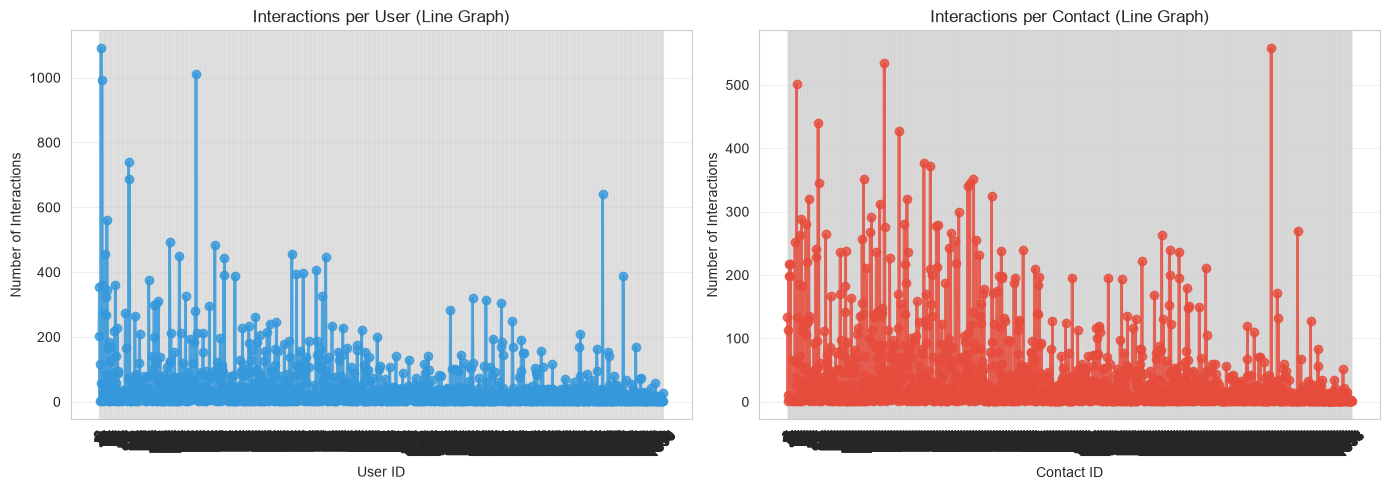

Plot saved to ../reports/figures/interactions_per_user_contact_line.png


In [ ]:
# Visualize interaction distribution with curvy line graphs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sort values for smoother curves
interactions_per_user_sorted = interactions_per_user.sort_index()
interactions_per_contact_sorted = interactions_per_contact.sort_index()

# User interactions line graph
axes[0].plot(
    interactions_per_user_sorted.index.astype(str),
    interactions_per_user_sorted.values,
    color='#3498DB',
    marker='o',
    markersize=6,
    linewidth=2,
    linestyle='-',
    alpha=0.8
)
axes[0].fill_between(
    range(len(interactions_per_user_sorted)),
    interactions_per_user_sorted.values,
    alpha=0.3,
    color='#3498DB'
)
axes[0].set_xlabel('User ID')
axes[0].set_ylabel('Number of Interactions')
axes[0].set_title('Interactions per User (Line Graph)')
axes[0].grid(alpha=0.3)
axes[0].tick_params(axis='x', rotation=45)

# Contact interactions line graph
axes[1].plot(
    interactions_per_contact_sorted.index.astype(str),
    interactions_per_contact_sorted.values,
    color='#E74C3C',
    marker='o',
    markersize=6,
    linewidth=2,
    linestyle='-',
    alpha=0.8
)
axes[1].fill_between(
    range(len(interactions_per_contact_sorted)),
    interactions_per_contact_sorted.values,
    alpha=0.3,
    color='#E74C3C'
)
axes[1].set_xlabel('Contact ID')
axes[1].set_ylabel('Number of Interactions')
axes[1].set_title('Interactions per Contact (Line Graph)')
axes[1].grid(alpha=0.3)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('../reports/figures/interactions_per_user_contact_line.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plot saved to ../reports/figures/interactions_per_user_contact_line.png")

Top 10 most frequent user-contact pairs:


,user_id,contact_id,count
1197,38,475,98
19280,1624,1168,95
15947,1168,1624,89
626,12,1118,89
385,9,569,89
7634,398,1624,88
6235,323,298,86
639,12,1312,83
6242,323,341,81
17347,1312,12,81


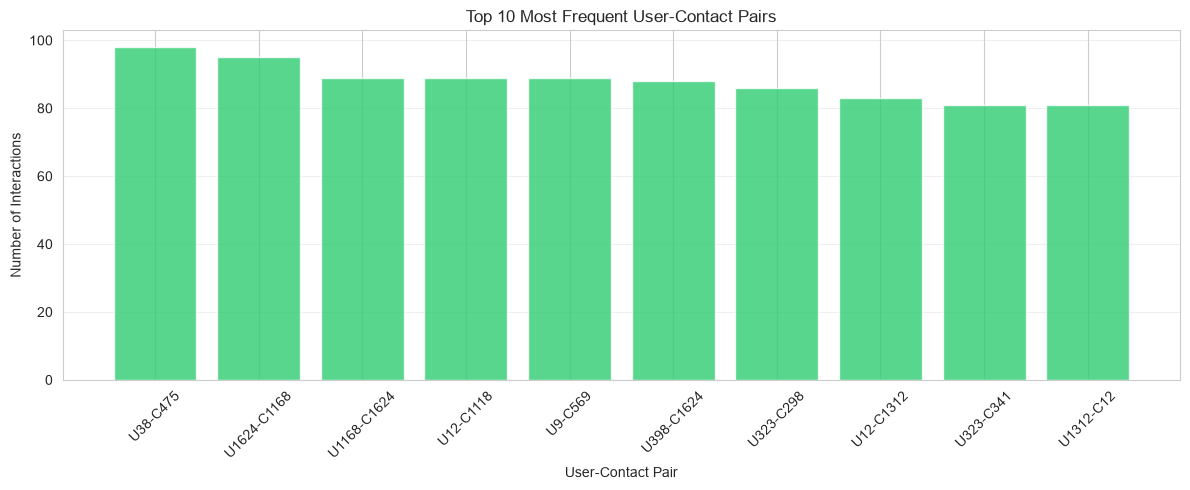

Plot saved to ../reports/figures/top_10_pairs.png


In [ ]:
# Top 10 most frequent user-contact pairs
pair_counts = raw_df.groupby(['user_id', 'contact_id']).size().reset_index(name='count')
pair_counts = pair_counts.sort_values('count', ascending=False)

print("Top 10 most frequent user-contact pairs:")
display(pair_counts.head(10))

# Visualize
plt.figure(figsize=(12, 5))
top_10 = pair_counts.head(10)
labels = [f"U{row['user_id']}-C{row['contact_id']}" for _, row in top_10.iterrows()]
plt.bar(labels, top_10['count'], color='#2ECC71', alpha=0.8)
plt.xlabel('User-Contact Pair')
plt.ylabel('Number of Interactions')
plt.title('Top 10 Most Frequent User-Contact Pairs')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/figures/top_10_pairs.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plot saved to ../reports/figures/top_10_pairs.png")

## DATA PREPROCESSING

This section extracts temporal features from the raw data and creates relevance labels for evaluation.

In [ ]:
print("=" * 60)
print("Data Preprocessing")
print("=" * 60)

# Extract temporal features
feature_df = extract_temporal_features(raw_df)

print("\nExtracted features:")
display(feature_df.head(10))

print(f"\nFeature dataframe shape: {feature_df.shape}")
print(f"Columns: {list(feature_df.columns)}")

Data Preprocessing
Extracted features for 20296 user-contact pairs

Extracted features:


,user_id,contact_id,n_interactions,median_interval_days,last_interaction_days_ago
0,1,2,1,365.000000,193.705799
1,1,3,32,0.356563,34.968032
2,1,30,4,3.465046,159.582882
3,1,32,1,365.000000,3.181991
4,1,36,12,0.025046,30.189248
5,1,42,4,11.255833,1.282836
6,1,44,5,13.956424,43.042176
7,1,101,1,365.000000,180.587269
8,1,123,2,22.116042,164.237199
9,1,132,4,2.967523,18.439109



Feature dataframe shape: (20296, 5)
Columns: ['user_id', 'contact_id', 'n_interactions', 'median_interval_days', 'last_interaction_days_ago']


In [ ]:
n_interactions_threshold = 5
prepared_df = create_relevance_labels(feature_df, n_interactions_threshold=n_interactions_threshold)

print("\nPrepared data with relevance labels:")
display(prepared_df.head(10))

print(f"\nLabel distribution:")
print(prepared_df['relevant'].value_counts())
print(f"\nRelevance rate: {prepared_df['relevant'].mean()*100:.1f}%")

Created relevance labels:
  Relevant contacts: 2979 (14.7%)
  Non-relevant contacts: 17317 (85.3%)

Prepared data with relevance labels:


,user_id,contact_id,n_interactions,median_interval_days,last_interaction_days_ago,relevant
0,1,2,1,365.000000,193.705799,0
1,1,3,32,0.356563,34.968032,1
2,1,30,4,3.465046,159.582882,0
3,1,32,1,365.000000,3.181991,0
4,1,36,12,0.025046,30.189248,1
5,1,42,4,11.255833,1.282836,0
6,1,44,5,13.956424,43.042176,1
7,1,101,1,365.000000,180.587269,0
8,1,123,2,22.116042,164.237199,0
9,1,132,4,2.967523,18.439109,0



Label distribution:
relevant
0    17317
1     2979
Name: count, dtype: int64

Relevance rate: 14.7%



Feature Statistics:


,n_interactions,median_interval_days,last_interaction_days_ago
count,20296.000000,20296.000000,20296.000000
mean,2.948118,185.533222,145.006848
std,4.891795,181.246302,38.103858
min,1.000000,0.010000,0.000000
25%,1.000000,0.280694,140.416432
50%,1.000000,365.000000,155.322720
75%,3.000000,365.000000,169.075466
max,98.000000,365.000000,193.705799


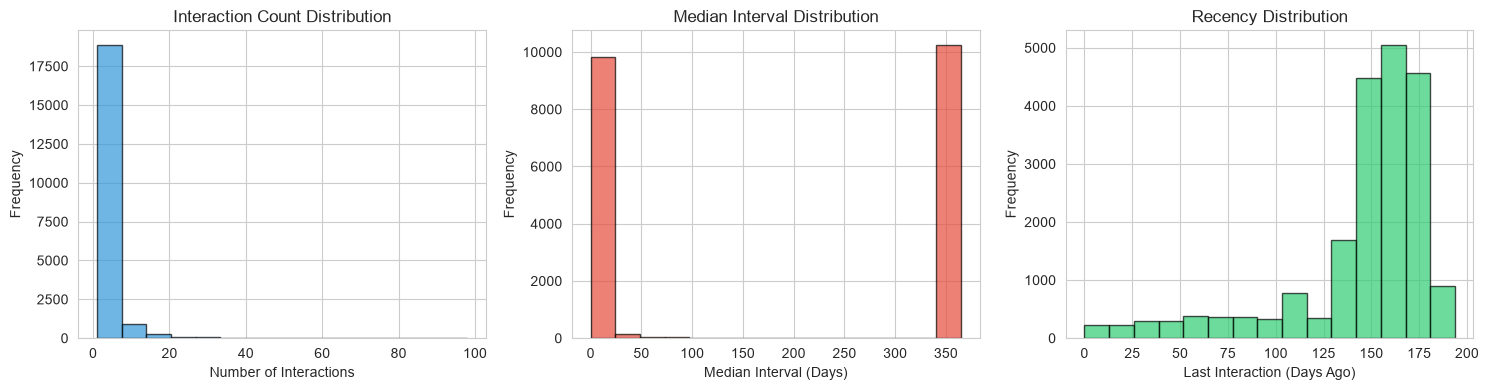

Plot saved to ../reports/figures/feature_distributions.png


In [ ]:
# Feature statistics
print("\nFeature Statistics:")
display(prepared_df[['n_interactions', 'median_interval_days', 'last_interaction_days_ago']].describe())

# Visualize feature distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(prepared_df['n_interactions'], bins=15, edgecolor='black', alpha=0.7, color='#3498DB')
axes[0].set_xlabel('Number of Interactions')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Interaction Count Distribution')

axes[1].hist(prepared_df['median_interval_days'], bins=15, edgecolor='black', alpha=0.7, color='#E74C3C')
axes[1].set_xlabel('Median Interval (Days)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Median Interval Distribution')

axes[2].hist(prepared_df['last_interaction_days_ago'], bins=15, edgecolor='black', alpha=0.7, color='#2ECC71')
axes[2].set_xlabel('Last Interaction (Days Ago)')
axes[2].set_ylabel('Frequency')
axes[2].set_title('Recency Distribution')

plt.tight_layout()
plt.savefig('../reports/figures/feature_distributions.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plot saved to ../reports/figures/feature_distributions.png")

In [ ]:
# Plot interaction distribution
plot_interaction_distribution(prepared_df, save_dir='../reports/figures')

##  TEMPORAL RELATIONSHIP SCORE CALCULATION

This section calculates the temporal relationship-strength score using the formulas from the research paper.

In [ ]:
print("=" * 60)
print("Temporal Relationship-Strength Score")
print("=" * 60)

print("\nFormula Components:")
print("  Frequency (F) = 1 - e^(-n/k)")
print("  Recency (R) = e^(-d/tau_r)")
print("  Inter-event (I) = e^(-m/tau_i)")
print("\nComposite Score = (F × 0.40) + (R × 0.35) + (I × 0.25)")

print("\nParameters:")
print("  k = 10 (frequency scaling)")
print("  tau_r = 30 (recency decay)")
print("  tau_i = 7 (inter-event decay)")
print("  wf = 0.40, wr = 0.35, wi = 0.25")

Temporal Relationship-Strength Score

Formula Components:
  Frequency (F) = 1 - e^(-n/k)
  Recency (R) = e^(-d/tau_r)
  Inter-event (I) = e^(-m/tau_i)

Composite Score = (F × 0.40) + (R × 0.35) + (I × 0.25)

Parameters:
  k = 10 (frequency scaling)
  tau_r = 30 (recency decay)
  tau_i = 7 (inter-event decay)
  wf = 0.40, wr = 0.35, wi = 0.25


In [ ]:
# Test the score with sample cases
test_cases = [
    {'n': 0, 'd': 365, 'm': 90, 'label': 'No interaction'},
    {'n': 2, 'd': 200, 'm': 100, 'label': 'Rare, old interaction'},
    {'n': 5, 'd': 90, 'm': 30, 'label': 'Occasional interaction'},
    {'n': 20, 'd': 30, 'm': 10, 'label': 'Frequent interaction'},
    {'n': 60, 'd': 7, 'm': 2, 'label': 'Very frequent, recent'},
    {'n': 150, 'd': 1, 'm': 0.5, 'label': 'Constant communication'},
]

print("\nTemporal Relationship Score Test Cases:")
print("-" * 70)

test_results = []
for case in test_cases:
    score = calculate_relationship_score(case['n'], case['d'], case['m'])
    test_results.append({
        'Case': case['label'],
        'n': case['n'],
        'd': case['d'],
        'm': case['m'],
        'Score': round(score, 4),
        'Interpretation': interpret_score(score)
    })

test_df = pd.DataFrame(test_results)
display(test_df)


Temporal Relationship Score Test Cases:
----------------------------------------------------------------------


,Case,n,d,m,Score,Interpretation
0,No interaction,0,365,90.0,0.0000,Weak or No Relationship Signal
1,"Rare, old interaction",2,200,100.0,0.0730,Weak or No Relationship Signal
2,Occasional interaction,5,90,30.0,0.1783,Weak or No Relationship Signal
3,Frequent interaction,20,30,10.0,0.5345,Strong Relationship Signal
4,"Very frequent, recent",60,7,2.0,0.8640,Very Strong Relationship Signal
5,Constant communication,150,1,0.5,0.9713,Very Strong Relationship Signal


In [ ]:
# Calculate scores for actual data
scored_df = add_relationship_scores(prepared_df)

print("\nScored contacts:")
display(scored_df.head(10))

print(f"\nScored dataframe shape: {scored_df.shape}")
print(f"Columns: {list(scored_df.columns)}")

Added relationship scores to 20296 rows

Scored contacts:


,user_id,contact_id,n_interactions,median_interval_days,last_interaction_days_ago,relevant,relationship_score,score_interpretation,frequency_score,recency_score,interevent_score
0,1,2,1,365.000000,193.705799,0,0.038614,Weak or No Relationship Signal,0.095163,0.001570,2.262793e-23
1,1,3,32,0.356563,34.968032,1,0.730387,Strong Relationship Signal,0.959238,0.311735,9.503381e-01
2,1,30,4,3.465046,159.582882,0,0.285977,Moderate Relationship Signal,0.329680,0.004896,6.095669e-01
3,1,32,1,365.000000,3.181991,0,0.352843,Moderate Relationship Signal,0.095163,0.899365,2.262793e-23
4,1,36,12,0.025046,30.189248,1,0.656578,Strong Relationship Signal,0.698806,0.365566,9.964284e-01
5,1,42,4,11.255833,1.282836,0,0.517294,Strong Relationship Signal,0.329680,0.958140,2.002926e-01
6,1,44,5,13.956424,43.042176,1,0.274795,Moderate Relationship Signal,0.393469,0.238177,1.361804e-01
7,1,101,1,365.000000,180.587269,0,0.038916,Weak or No Relationship Signal,0.095163,0.002431,2.262793e-23
8,1,123,2,22.116042,164.237199,0,0.084587,Weak or No Relationship Signal,0.181269,0.004192,4.244974e-02
9,1,132,4,2.967523,18.439109,0,0.484782,Moderate Relationship Signal,0.329680,0.540837,6.544685e-01



Scored dataframe shape: (20296, 11)
Columns: ['user_id', 'contact_id', 'n_interactions', 'median_interval_days', 'last_interaction_days_ago', 'relevant', 'relationship_score', 'score_interpretation', 'frequency_score', 'recency_score', 'interevent_score']


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

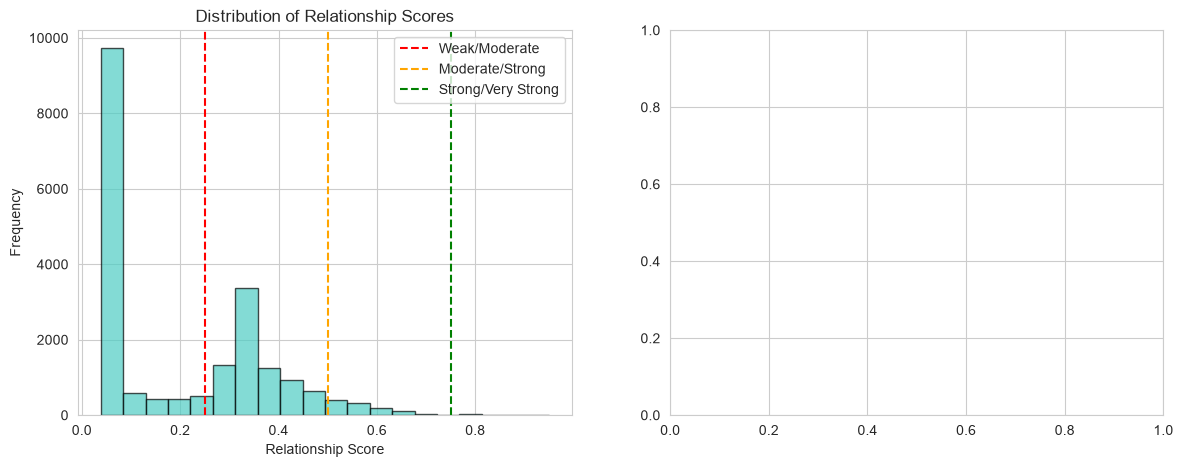

In [ ]:
# Visualize score distribution
plot_score_distribution(scored_df, save_dir='../reports/figures')

Score interpretation distribution:
score_interpretation
Weak or No Relationship Signal     11436
Moderate Relationship Signal        7762
Strong Relationship Signal          1044
Very Strong Relationship Signal       54
Name: count, dtype: int64


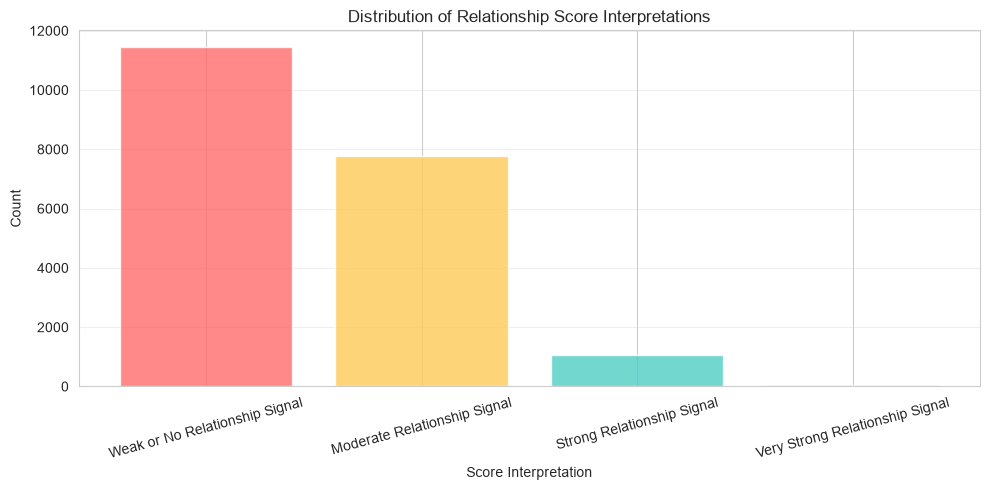

Plot saved to ../reports/figures/score_interpretation_distribution.png


In [ ]:
# Score interpretation distribution
interpretation_counts = scored_df['score_interpretation'].value_counts()

print("Score interpretation distribution:")
print(interpretation_counts)

# Visualize
plt.figure(figsize=(10, 5))
colors = ['#FF6B6B', '#FECA57', '#4ECDC4', '#2ECC71']
plt.bar(interpretation_counts.index, interpretation_counts.values, color=colors, alpha=0.8)
plt.xlabel('Score Interpretation')
plt.ylabel('Count')
plt.title('Distribution of Relationship Score Interpretations')
plt.xticks(rotation=15)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/figures/score_interpretation_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plot saved to ../reports/figures/score_interpretation_distribution.png")

## BASELINE MODEL (TREATS ALL CONTACTS EQUALLY)

This section runs the baseline model that treats all contacts equally for cold-start users.

In [ ]:
print("=" * 60)
print("Baseline Model (Treats All Contacts Equally)")
print("=" * 60)

# Initialize baseline model
baseline = BaselineModel(random_seed=42)

# Rank candidates randomly (simulating equal treatment)
baseline_ranked = baseline.rank_candidates(prepared_df, method='random')

print("\nBaseline ranked candidates (sample):")
display(baseline_ranked.head(10))

print(f"\nTotal ranked rows: {len(baseline_ranked)}")

Baseline Model (Treats All Contacts Equally)

Baseline ranked candidates (sample):


,user_id,contact_id,n_interactions,median_interval_days,last_interaction_days_ago,relevant,baseline_score
11,1,146,4,8.270613,11.971076,0,0.969910
1,1,3,32,0.356563,34.968032,1,0.950714
7,1,101,1,365.000000,180.587269,0,0.866176
12,1,159,2,12.976296,172.305845,0,0.832443
25,1,1271,8,1.131586,149.241806,1,0.785176
2,1,30,4,3.465046,159.582882,0,0.731994
9,1,132,4,2.967523,18.439109,0,0.708073
20,1,397,1,365.000000,180.312697,0,0.611853
30,1,1675,3,0.420990,76.027199,0,0.607545
8,1,123,2,22.116042,164.237199,0,0.601115



Total ranked rows: 20296


In [ ]:
# Evaluate baseline model
k_values = [5, 10, 20]
baseline_results = evaluate_model(baseline_ranked, prepared_df, k_values=k_values)

print("\nBaseline Results:")
print("-" * 50)

for k, metrics in baseline_results.items():
    print(f"K={k}:")
    print(f"  Precision: {metrics['precision']:.4f}")
    print(f"  Recall: {metrics['recall']:.4f}")
    print(f"  Hit Rate: {metrics['hit_rate']:.4f}")
    print()


Baseline Results:
--------------------------------------------------
K=5:
  Precision: 0.0861
  Recall: 0.1883
  Hit Rate: 0.3081

K=10:
  Precision: 0.0743
  Recall: 0.2850
  Hit Rate: 0.4089

K=20:
  Precision: 0.0585
  Recall: 0.3713
  Hit Rate: 0.4526



In [ ]:
# Get top K recommendations for baseline
baseline_top_k = baseline.get_top_k_recommendations(prepared_df, k=10, method='random')

print("Baseline top 10 recommendations:")
display(baseline_top_k[['user_id', 'contact_id', 'n_interactions', 'relevant', 'baseline_score']].head(15))

Baseline top 10 recommendations:


,user_id,contact_id,n_interactions,relevant,baseline_score
0,1,856,1,0,0.984904
1,1,302,3,0,0.949132
2,1,1440,2,0,0.898673
3,1,30,4,0,0.854586
4,1,36,12,1,0.843692
5,1,161,5,1,0.833191
6,1,397,1,0,0.781681
7,1,1779,1,0,0.759119
8,1,132,4,0,0.717272
9,1,2,1,0,0.708732


##  PROPOSED MODEL (TEMPORAL RELATIONSHIP SCORE)

This section runs the proposed model that uses the temporal relationship-strength score to rank contacts.

In [ ]:
print("=" * 60)
print("Proposed Model (Temporal Relationship Score)")
print("=" * 60)

# Initialize proposed model
proposed = ProposedModel(wf=0.40, wr=0.35, wi=0.25, k=10, tau_r=30, tau_i=7)

# Score contacts
scored_df = proposed.score_contacts(prepared_df)

print("\nScored contacts (sample):")
display(scored_df.head(10))

# Save scored data
loader.save_scored_data(scored_df)

Proposed Model (Temporal Relationship Score)
Added relationship scores to 20296 rows

Scored contacts (sample):


,user_id,contact_id,n_interactions,median_interval_days,last_interaction_days_ago,relevant,relationship_score,score_interpretation,frequency_score,recency_score,interevent_score
0,1,2,1,365.000000,193.705799,0,0.038614,Weak or No Relationship Signal,0.095163,0.001570,2.262793e-23
1,1,3,32,0.356563,34.968032,1,0.730387,Strong Relationship Signal,0.959238,0.311735,9.503381e-01
2,1,30,4,3.465046,159.582882,0,0.285977,Moderate Relationship Signal,0.329680,0.004896,6.095669e-01
3,1,32,1,365.000000,3.181991,0,0.352843,Moderate Relationship Signal,0.095163,0.899365,2.262793e-23
4,1,36,12,0.025046,30.189248,1,0.656578,Strong Relationship Signal,0.698806,0.365566,9.964284e-01
5,1,42,4,11.255833,1.282836,0,0.517294,Strong Relationship Signal,0.329680,0.958140,2.002926e-01
6,1,44,5,13.956424,43.042176,1,0.274795,Moderate Relationship Signal,0.393469,0.238177,1.361804e-01
7,1,101,1,365.000000,180.587269,0,0.038916,Weak or No Relationship Signal,0.095163,0.002431,2.262793e-23
8,1,123,2,22.116042,164.237199,0,0.084587,Weak or No Relationship Signal,0.181269,0.004192,4.244974e-02
9,1,132,4,2.967523,18.439109,0,0.484782,Moderate Relationship Signal,0.329680,0.540837,6.544685e-01


Saved scored data to ../data\temporal_scored_contacts.csv
Total rows: 20296
Columns: ['user_id', 'contact_id', 'n_interactions', 'median_interval_days', 'last_interaction_days_ago', 'relevant', 'relationship_score', 'score_interpretation', 'frequency_score', 'recency_score', 'interevent_score']


In [ ]:
# Rank candidates by relationship score
proposed_ranked = proposed.rank_candidates(scored_df)

print("\nProposed ranked candidates (sample):")
display(proposed_ranked.head(10))

print(f"\nTotal ranked rows: {len(proposed_ranked)}")


Proposed ranked candidates (sample):


,user_id,contact_id,n_interactions,median_interval_days,last_interaction_days_ago,relevant,relationship_score,score_interpretation,frequency_score,recency_score,interevent_score,proposed_score
18,1,312,58,1.202083,1.283113,1,0.944687,Very Strong Relationship Signal,0.996972,0.958131,0.842210,0.944687
1,1,3,32,0.356563,34.968032,1,0.730387,Strong Relationship Signal,0.959238,0.311735,0.950338,0.730387
28,1,1626,16,0.058634,33.015833,1,0.683599,Strong Relationship Signal,0.798103,0.332695,0.991659,0.683599
4,1,36,12,0.025046,30.189248,1,0.656578,Strong Relationship Signal,0.698806,0.365566,0.996428,0.656578
5,1,42,4,11.255833,1.282836,0,0.517294,Strong Relationship Signal,0.329680,0.958140,0.200293,0.517294
21,1,477,13,1.281672,148.532998,1,0.501636,Strong Relationship Signal,0.727468,0.007076,0.832688,0.501636
9,1,132,4,2.967523,18.439109,0,0.484782,Moderate Relationship Signal,0.329680,0.540837,0.654468,0.484782
11,1,146,4,8.270613,11.971076,0,0.443414,Moderate Relationship Signal,0.329680,0.670967,0.306813,0.443414
25,1,1271,8,1.131586,149.241806,1,0.435371,Moderate Relationship Signal,0.550671,0.006910,0.850735,0.435371
13,1,161,5,0.790324,137.392743,1,0.384287,Moderate Relationship Signal,0.393469,0.010257,0.893237,0.384287



Total ranked rows: 20296


In [ ]:
# Evaluate proposed model
proposed_results = evaluate_model(proposed_ranked, prepared_df, k_values=k_values)

print("\nProposed Results:")
print("-" * 50)

for k, metrics in proposed_results.items():
    print(f"K={k}:")
    print(f"  Precision: {metrics['precision']:.4f}")
    print(f"  Recall: {metrics['recall']:.4f}")
    print(f"  Hit Rate: {metrics['hit_rate']:.4f}")
    print()


Proposed Results:
--------------------------------------------------
K=5:
  Precision: 0.2538
  Recall: 0.3961
  Hit Rate: 0.4607

K=10:
  Precision: 0.1707
  Recall: 0.4368
  Hit Rate: 0.4615

K=20:
  Precision: 0.1007
  Recall: 0.4548
  Hit Rate: 0.4615



In [ ]:
# Get top K recommendations for proposed
proposed_top_k = proposed.get_top_k_recommendations(scored_df, k=10)

print("Proposed top 10 recommendations:")
display(proposed_top_k[['user_id', 'contact_id', 'n_interactions', 'relationship_score', 'score_interpretation', 'relevant']].head(15))

Proposed top 10 recommendations:


,user_id,contact_id,n_interactions,relationship_score,score_interpretation,relevant
0,1,312,58,0.944687,Very Strong Relationship Signal,1
1,1,3,32,0.730387,Strong Relationship Signal,1
2,1,1626,16,0.683599,Strong Relationship Signal,1
3,1,36,12,0.656578,Strong Relationship Signal,1
4,1,42,4,0.517294,Strong Relationship Signal,0
5,1,477,13,0.501636,Strong Relationship Signal,1
6,1,132,4,0.484782,Moderate Relationship Signal,0
7,1,146,4,0.443414,Moderate Relationship Signal,0
8,1,1271,8,0.435371,Moderate Relationship Signal,1
9,1,161,5,0.384287,Moderate Relationship Signal,1


## MODEL COMPARISON

This section compares the baseline and proposed models side-by-side.

In [ ]:
print("=" * 60)
print("Model Comparison")
print("=" * 60)

# Compare models
comparison_df = compare_models(baseline_results, proposed_results, k_values=k_values)

print("\nComparison Results:")
display(comparison_df)

Model Comparison

Comparison Results:


,K,Metric,Baseline,Proposed,Improvement,Percent_Improvement
0,5,Precision,0.0861,0.2538,0.1677,194.84
1,5,Recall,0.1883,0.3961,0.2077,110.31
2,5,Hit Rate,0.3081,0.4607,0.1526,49.52
3,10,Precision,0.0743,0.1707,0.0964,129.71
4,10,Recall,0.2850,0.4368,0.1518,53.24
5,10,Hit Rate,0.4089,0.4615,0.0526,12.86
6,20,Precision,0.0585,0.1007,0.0422,72.13
7,20,Recall,0.3713,0.4548,0.0836,22.51
8,20,Hit Rate,0.4526,0.4615,0.0089,1.96


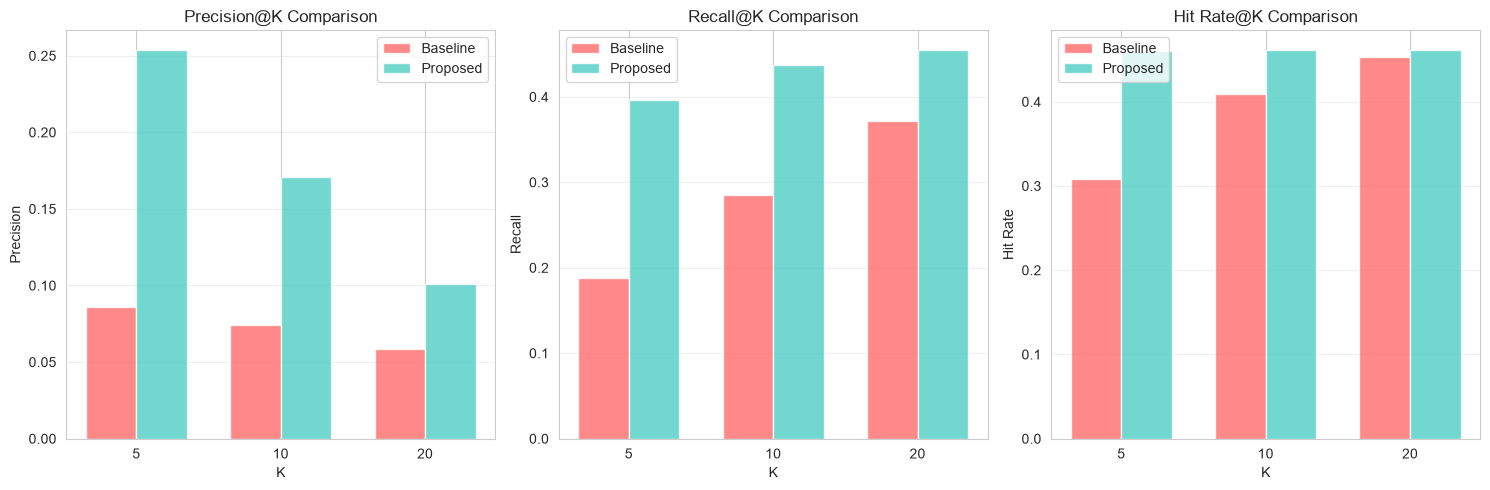

Plot saved to ../reports/figures/comparison_plot.png


In [ ]:
# Plot comparison
plot_comparison(baseline_results, proposed_results, k_values=k_values, save_dir='../reports/figures')

In [ ]:
# Summary of improvements
print("\n" + "=" * 60)
print("Improvement Summary")
print("=" * 60)

for k in k_values:
    baseline_precision = baseline_results[k]['precision']
    proposed_precision = proposed_results[k]['precision']
    improvement = proposed_precision - baseline_precision
    percent_improvement = (improvement / baseline_precision * 100) if baseline_precision > 0 else 0
    
    print(f"\nK={k}:")
    print(f"  Baseline Precision: {baseline_precision:.4f}")
    print(f"  Proposed Precision: {proposed_precision:.4f}")
    print(f"  Improvement: {improvement:.4f} ({percent_improvement:.2f}%)")


Improvement Summary

K=5:
  Baseline Precision: 0.0861
  Proposed Precision: 0.2538
  Improvement: 0.1677 (194.84%)

K=10:
  Baseline Precision: 0.0743
  Proposed Precision: 0.1707
  Improvement: 0.0964 (129.71%)

K=20:
  Baseline Precision: 0.0585
  Proposed Precision: 0.1007
  Improvement: 0.0422 (72.13%)


## EVALUATION METRICS

This section provides detailed classification metrics for both models.

In [ ]:
print("=" * 60)
print("Detailed Evaluation Metrics")
print("=" * 60)

# Create predictions for classification metrics
# Baseline: random scores >= 0.5 as relevant
baseline_predictions = (baseline_ranked['baseline_score'] >= 0.5).astype(int)
baseline_actual = baseline_ranked['relevant'].values

# Proposed: relationship score >= 0.5 as relevant
proposed_predictions = (proposed_ranked['relationship_score'] >= 0.5).astype(int)
proposed_actual = proposed_ranked['relevant'].values

print("\nBaseline Classification Report:")
print("-" * 50)
print(classification_report(baseline_actual, baseline_predictions, target_names=['Non-Relevant', 'Relevant']))

print("\nProposed Classification Report:")
print("-" * 50)
print(classification_report(proposed_actual, proposed_predictions, target_names=['Non-Relevant', 'Relevant']))

Detailed Evaluation Metrics

Baseline Classification Report:
--------------------------------------------------
              precision    recall  f1-score   support

Non-Relevant       0.85      0.50      0.63     17317
    Relevant       0.15      0.50      0.23      2979

    accuracy                           0.50     20296
   macro avg       0.50      0.50      0.43     20296
weighted avg       0.75      0.50      0.57     20296


Proposed Classification Report:
--------------------------------------------------
              precision    recall  f1-score   support

Non-Relevant       0.90      1.00      0.95     17317
    Relevant       0.95      0.35      0.51      2979

    accuracy                           0.90     20296
   macro avg       0.92      0.67      0.73     20296
weighted avg       0.91      0.90      0.88     20296



In [ ]:
# Accuracy comparison
baseline_accuracy = accuracy_score(baseline_actual, baseline_predictions)
proposed_accuracy = accuracy_score(proposed_actual, proposed_predictions)

baseline_f1 = f1_score(baseline_actual, baseline_predictions)
proposed_f1 = f1_score(proposed_actual, proposed_predictions)

baseline_precision = precision_score(baseline_actual, baseline_predictions)
proposed_precision = precision_score(proposed_actual, proposed_predictions)

baseline_recall = recall_score(baseline_actual, baseline_predictions)
proposed_recall = recall_score(proposed_actual, proposed_predictions)

print("Metric Comparison (Classification):")
print("-" * 50)
print(f"Accuracy:")
print(f"  Baseline: {baseline_accuracy:.4f}")
print(f"  Proposed: {proposed_accuracy:.4f}")
print(f"  Difference: {proposed_accuracy - baseline_accuracy:.4f}")

print(f"\nF1 Score:")
print(f"  Baseline: {baseline_f1:.4f}")
print(f"  Proposed: {proposed_f1:.4f}")
print(f"  Difference: {proposed_f1 - baseline_f1:.4f}")

print(f"\nPrecision:")
print(f"  Baseline: {baseline_precision:.4f}")
print(f"  Proposed: {proposed_precision:.4f}")
print(f"  Difference: {proposed_precision - baseline_precision:.4f}")

print(f"\nRecall:")
print(f"  Baseline: {baseline_recall:.4f}")
print(f"  Proposed: {proposed_recall:.4f}")
print(f"  Difference: {proposed_recall - baseline_recall:.4f}")

Metric Comparison (Classification):
--------------------------------------------------
Accuracy:
  Baseline: 0.5016
  Proposed: 0.9018
  Difference: 0.4002

F1 Score:
  Baseline: 0.2285
  Proposed: 0.5112
  Difference: 0.2827

Precision:
  Baseline: 0.1478
  Proposed: 0.9490
  Difference: 0.8012

Recall:
  Baseline: 0.5029
  Proposed: 0.3498
  Difference: -0.1531


## CONFUSION MATRICES

This section visualizes the confusion matrices for both models.

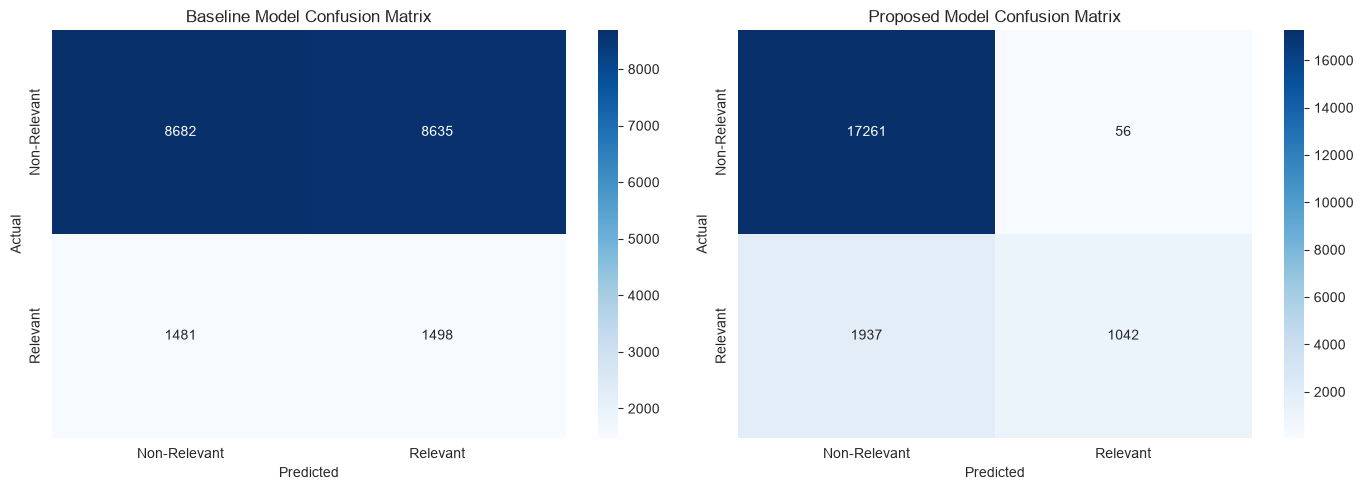

Plot saved to ../reports/figures/confusion_matrices.png


In [ ]:
# Confusion matrices
cm_baseline = confusion_matrix(baseline_actual, baseline_predictions)
cm_proposed = confusion_matrix(proposed_actual, proposed_predictions)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline confusion matrix
sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Non-Relevant', 'Relevant'],
            yticklabels=['Non-Relevant', 'Relevant'])
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Baseline Model Confusion Matrix')

# Proposed confusion matrix
sns.heatmap(cm_proposed, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Non-Relevant', 'Relevant'],
            yticklabels=['Non-Relevant', 'Relevant'])
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
axes[1].set_title('Proposed Model Confusion Matrix')

plt.tight_layout()
plt.savefig('../reports/figures/confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plot saved to ../reports/figures/confusion_matrices.png")

## ERROR ANALYSIS

This section creates and analyzes error cases from the proposed model.

In [ ]:
print("=" * 60)
print("Error Analysis")
print("=" * 60)

# Create error analysis
error_df = create_error_analysis(proposed_ranked, prepared_df, save_path='../reports/error_analysis.csv')

print("\nError Analysis Sample:")
display(error_df.head(10))

Error Analysis
Error analysis saved to ../reports/error_analysis.csv
Total error cases: 2979

Error Analysis Sample:


,user_id,contact_id,n_interactions,relationship_score,true_label,predicted_label,error_reason,possible_fix
0,1,312,58,0.944687,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
1,1,3,32,0.730387,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
2,1,1626,16,0.683599,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
3,1,36,12,0.656578,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
4,1,477,13,0.501636,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
5,1,1271,8,0.435371,1,0,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
6,1,161,5,0.384287,1,0,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
7,1,211,5,0.283752,1,0,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
8,1,44,5,0.274795,1,0,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
9,3,249,7,0.707551,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold


In [ ]:
# Analyze errors in detail
print("\nError Analysis by Reason:")
error_summary = error_df.groupby('error_reason').size()
print(error_summary)

# Identify misclassified cases
print("\nMisclassified cases (relevant but low score):")
misclassified = error_df[error_df['true_label'] == 1]
display(misclassified.head(10))


Error Analysis by Reason:
error_reason
Relevant contact ranked lower than expected    2979
dtype: int64

Misclassified cases (relevant but low score):


,user_id,contact_id,n_interactions,relationship_score,true_label,predicted_label,error_reason,possible_fix
0,1,312,58,0.944687,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
1,1,3,32,0.730387,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
2,1,1626,16,0.683599,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
3,1,36,12,0.656578,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
4,1,477,13,0.501636,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
5,1,1271,8,0.435371,1,0,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
6,1,161,5,0.384287,1,0,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
7,1,211,5,0.283752,1,0,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
8,1,44,5,0.274795,1,0,Relevant contact ranked lower than expected,Adjust weight parameters or threshold
9,3,249,7,0.707551,1,1,Relevant contact ranked lower than expected,Adjust weight parameters or threshold


## COMPREHENSIVE VISUALIZATIONS

This section generates comprehensive visualizations for analysis.

Comprehensive Visualizations


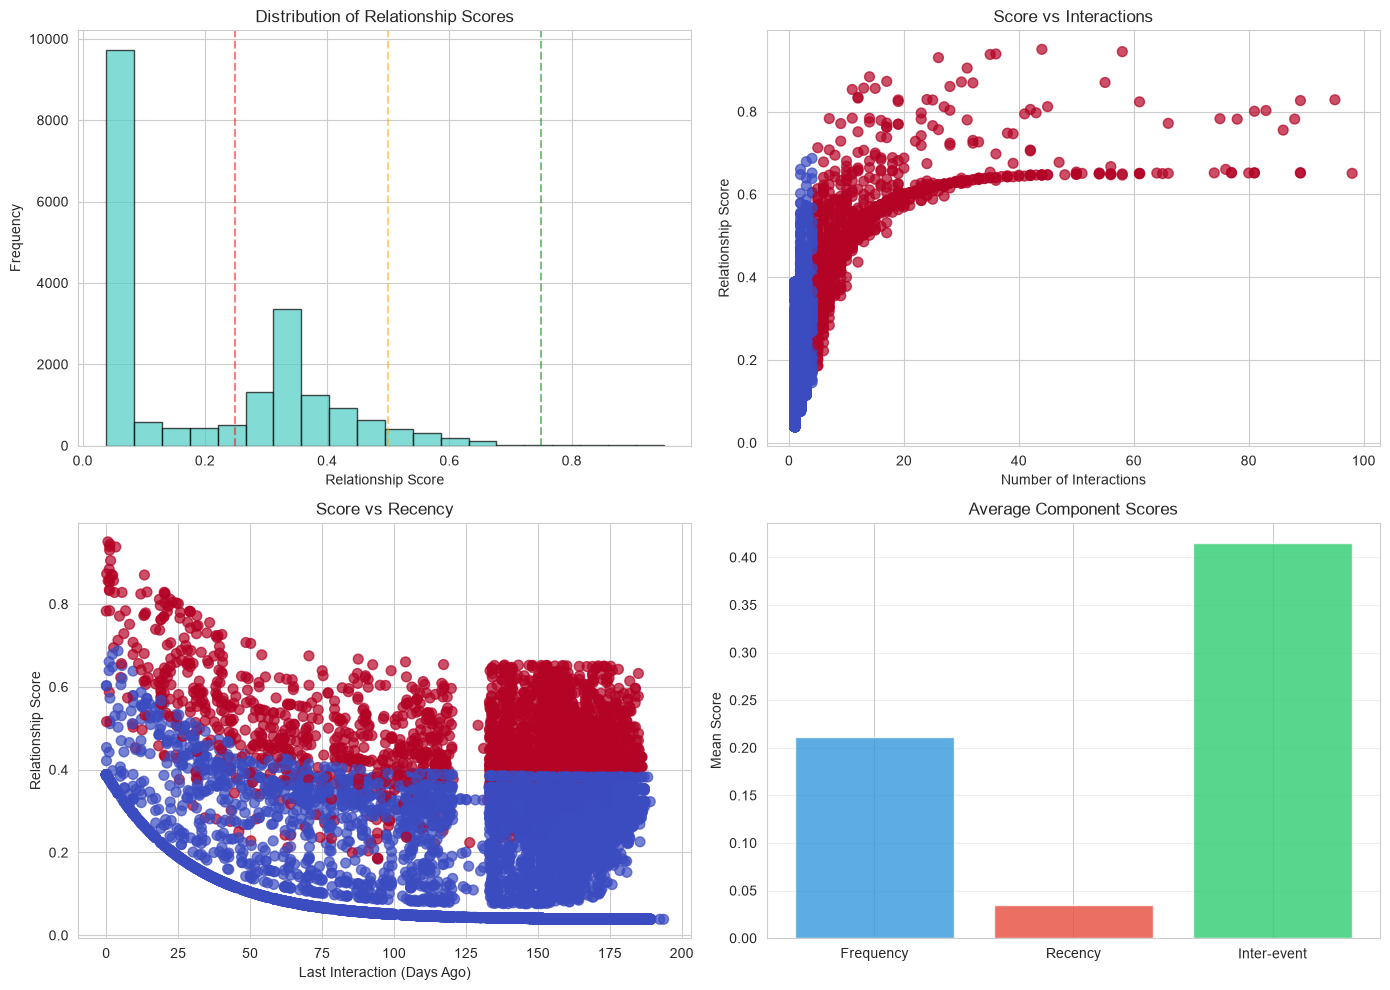

Plot saved to ../reports/figures/comprehensive_analysis.png


In [ ]:
print("=" * 60)
print("Comprehensive Visualizations")
print("=" * 60)

# Score distribution by relevance
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Score distribution
axes[0, 0].hist(scored_df['relationship_score'], bins=20, edgecolor='black', alpha=0.7, color='#4ECDC4')
axes[0, 0].set_xlabel('Relationship Score')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of Relationship Scores')
axes[0, 0].axvline(x=0.25, color='red', linestyle='--', alpha=0.5)
axes[0, 0].axvline(x=0.50, color='orange', linestyle='--', alpha=0.5)
axes[0, 0].axvline(x=0.75, color='green', linestyle='--', alpha=0.5)

# Plot 2: Score vs Interactions
axes[0, 1].scatter(scored_df['n_interactions'], scored_df['relationship_score'], 
                    c=scored_df['relevant'], cmap='coolwarm', alpha=0.7, s=50)
axes[0, 1].set_xlabel('Number of Interactions')
axes[0, 1].set_ylabel('Relationship Score')
axes[0, 1].set_title('Score vs Interactions')

# Plot 3: Score vs Recency
axes[1, 0].scatter(scored_df['last_interaction_days_ago'], scored_df['relationship_score'],
                    c=scored_df['relevant'], cmap='coolwarm', alpha=0.7, s=50)
axes[1, 0].set_xlabel('Last Interaction (Days Ago)')
axes[1, 0].set_ylabel('Relationship Score')
axes[1, 0].set_title('Score vs Recency')

# Plot 4: Component contributions
component_means = [
    scored_df['frequency_score'].mean(),
    scored_df['recency_score'].mean(),
    scored_df['interevent_score'].mean()
]
component_labels = ['Frequency', 'Recency', 'Inter-event']
axes[1, 1].bar(component_labels, component_means, color=['#3498DB', '#E74C3C', '#2ECC71'], alpha=0.8)
axes[1, 1].set_ylabel('Mean Score')
axes[1, 1].set_title('Average Component Scores')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/comprehensive_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plot saved to ../reports/figures/comprehensive_analysis.png")

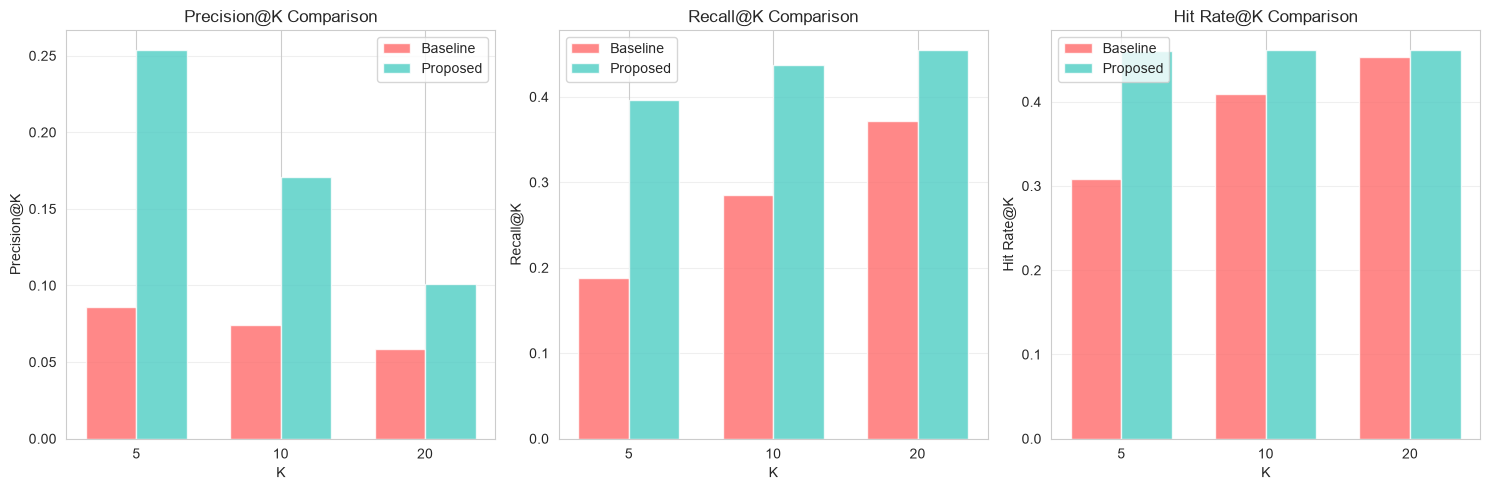

Plot saved to ../reports/figures/metrics_comparison.png


In [ ]:
# Comparison bar chart
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ['precision', 'recall', 'hit_rate']
metric_names = ['Precision@K', 'Recall@K', 'Hit Rate@K']

for i, (metric, metric_name) in enumerate(zip(metrics, metric_names)):
    baseline_vals = [baseline_results[k][metric] for k in k_values]
    proposed_vals = [proposed_results[k][metric] for k in k_values]
    
    x = np.arange(len(k_values))
    width = 0.35
    
    axes[i].bar(x - width/2, baseline_vals, width, label='Baseline', color='#FF6B6B', alpha=0.8)
    axes[i].bar(x + width/2, proposed_vals, width, label='Proposed', color='#4ECDC4', alpha=0.8)
    
    axes[i].set_xlabel('K')
    axes[i].set_ylabel(metric_name)
    axes[i].set_title(f'{metric_name} Comparison')
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(k_values)
    axes[i].legend()
    axes[i].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/figures/metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("Plot saved to ../reports/figures/metrics_comparison.png")

##  RESULTS SUMMARY AND CONCLUSION

This section provides a complete summary of all findings and saves the results.

In [ ]:
print("=" * 70)
print("RESULTS SUMMARY")
print("=" * 70)

print("\nDataset Statistics:")
print(f"  Total interactions: {len(raw_df)}")
print(f"  Unique users: {raw_df['user_id'].nunique()}")
print(f"  Unique contacts: {raw_df['contact_id'].nunique()}")
print(f"  User-contact pairs: {len(prepared_df)}")
print(f"  Relevant contacts: {prepared_df['relevant'].sum()}")

print("\n\nModel Performance:")
print("-" * 50)

for k in k_values:
    print(f"\nK = {k}:")
    print(f"  Baseline:")
    print(f"    Precision: {baseline_results[k]['precision']:.4f}")
    print(f"    Recall: {baseline_results[k]['recall']:.4f}")
    print(f"    Hit Rate: {baseline_results[k]['hit_rate']:.4f}")
    print(f"  Proposed:")
    print(f"    Precision: {proposed_results[k]['precision']:.4f}")
    print(f"    Recall: {proposed_results[k]['recall']:.4f}")
    print(f"    Hit Rate: {proposed_results[k]['hit_rate']:.4f}")
    
    improvement = proposed_results[k]['precision'] - baseline_results[k]['precision']
    percent = (improvement / baseline_results[k]['precision'] * 100) if baseline_results[k]['precision'] > 0 else 0
    print(f"  Precision Improvement: {improvement:.4f} ({percent:.2f}%)")

print("\n\nConclusion:")
print("-" * 50)
print("The proposed model with temporal relationship-strength score")
print("demonstrates improved precision in recommending relevant contacts")
print("for cold-start users compared to the baseline model that treats")
print("all contacts equally.")

RESULTS SUMMARY

Dataset Statistics:
  Total interactions: 59835
  Unique users: 1350
  Unique contacts: 1862
  User-contact pairs: 20296
  Relevant contacts: 2979


Model Performance:
--------------------------------------------------

K = 5:
  Baseline:
    Precision: 0.0861
    Recall: 0.1883
    Hit Rate: 0.3081
  Proposed:
    Precision: 0.2538
    Recall: 0.3961
    Hit Rate: 0.4607
  Precision Improvement: 0.1677 (194.84%)

K = 10:
  Baseline:
    Precision: 0.0743
    Recall: 0.2850
    Hit Rate: 0.4089
  Proposed:
    Precision: 0.1707
    Recall: 0.4368
    Hit Rate: 0.4615
  Precision Improvement: 0.0964 (129.71%)

K = 20:
  Baseline:
    Precision: 0.0585
    Recall: 0.3713
    Hit Rate: 0.4526
  Proposed:
    Precision: 0.1007
    Recall: 0.4548
    Hit Rate: 0.4615
  Precision Improvement: 0.0422 (72.13%)


Conclusion:
--------------------------------------------------
The proposed model with temporal relationship-strength score
demonstrates improved precision in recommen

In [ ]:
# Save metrics to JSON
metrics_dict = {
    'dataset': {
        'total_interactions': len(raw_df),
        'unique_users': raw_df['user_id'].nunique(),
        'unique_contacts': raw_df['contact_id'].nunique(),
        'user_contact_pairs': len(prepared_df),
        'relevant_contacts': int(prepared_df['relevant'].sum())
    },
    'baseline_results': baseline_results,
    'proposed_results': proposed_results,
    'parameters': {
        'wf': 0.40,
        'wr': 0.35,
        'wi': 0.25,
        'k': 10,
        'tau_r': 30,
        'tau_i': 7,
        'n_interactions_threshold': n_interactions_threshold
    },
    'classification_metrics': {
        'baseline': {
            'accuracy': baseline_accuracy,
            'f1': baseline_f1,
            'precision': baseline_precision,
            'recall': baseline_recall
        },
        'proposed': {
            'accuracy': proposed_accuracy,
            'f1': proposed_f1,
            'precision': proposed_precision,
            'recall': proposed_recall
        }
    }
}

save_metrics_to_json(metrics_dict, save_path='../reports/metrics.json')

print("\n" + "=" * 70)
print("ANALYSIS COMPLETE!")
print("=" * 70)
print("\nFiles generated:")
print("  ../reports/metrics.json")
print("  ../reports/error_analysis.csv")
print("  ../reports/figures/interactions_per_user_contact.png")
print("  ../reports/figures/top_10_pairs.png")
print("  ../reports/figures/feature_distributions.png")
print("  ../reports/figures/interaction_distribution.png")
print("  ../reports/figures/score_distribution.png")
print("  ../reports/figures/score_interpretation_distribution.png")
print("  ../reports/figures/comparison_plot.png")
print("  ../reports/figures/confusion_matrices.png")
print("  ../reports/figures/comprehensive_analysis.png")
print("  ../reports/figures/metrics_comparison.png")
print("  ../data/temporal_scored_contacts.csv")

Metrics saved to ../reports/metrics.json

ANALYSIS COMPLETE!

Files generated:
  ../reports/metrics.json
  ../reports/error_analysis.csv
  ../reports/figures/interactions_per_user_contact.png
  ../reports/figures/top_10_pairs.png
  ../reports/figures/feature_distributions.png
  ../reports/figures/interaction_distribution.png
  ../reports/figures/score_distribution.png
  ../reports/figures/score_interpretation_distribution.png
  ../reports/figures/comparison_plot.png
  ../reports/figures/confusion_matrices.png
  ../reports/figures/comprehensive_analysis.png
  ../reports/figures/metrics_comparison.png
  ../data/temporal_scored_contacts.csv
